# 05 — Model Training & Comparison
### Project: Subscription Churn Prediction & Risk Scoring

---

### Objective of this Notebook:
Now that we have our engineered features, we want to train machine learning models to **predict which customers will churn**.

In this notebook, we:
1. **Load Data**: Read `data/processed/customer_features.csv`.
2. **One-Hot Encoding**: Convert text columns into numbers using `pd.get_dummies()`.
3. **Train / Test Split**: 80% to train the model, 20% to test it.
4. **Train 3 Models**:
   - Logistic Regression
   - Random Forest
   - Gradient Boosting
5. **Compare Models**: Accuracy, Precision, Recall, F1-Score, and ROC-AUC.
6. **Feature Importance**: See which signals matter most in predicting churn.

## Step 1: Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay
)

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)

print("Libraries imported successfully!")

Libraries imported successfully!


## Step 2: Load the Processed Customer Features

In [6]:
# Read customer features dataset
df = pd.read_csv('C:/Users/Admin/OneDrive/Data Analyst Project/Subscription Churn Prediction & Risk Scoring/data/processed/customer_features.csv')


print(f"Loaded {len(df):,} customers with {df.shape[1]} columns.")
display(df.head(3))

Loaded 20,000 customers with 29 columns.


,customer_id,tenure_months,age_group,gender,region,acquisition_channel,plan,billing_cycle,monthly_fee,discount_pct,...,total_payments,failed_payments,payment_failure_rate,had_failed_payment,total_tickets,avg_resolution_hours,avg_csat,had_low_csat,tickets_per_tenure_month,churn_flag
0,CUST-10000,26,35-44,Male,North America,Paid Ads,Basic,Monthly,15.0,0,...,27,3,0.111,1,2,8.85,3.50,0,0.074,0
1,CUST-10001,15,18-24,Female,Latin America,Organic Search,Basic,Annual,13.5,10,...,2,1,0.500,1,3,16.80,3.00,1,0.188,0
2,CUST-10002,1,45-54,Male,Asia-Pacific,Organic Search,Basic,Monthly,15.0,0,...,2,0,0.000,0,3,11.23,4.33,0,1.500,0


## Step 3: Separate Features (X) and Target (y)

In [7]:
# X = all predictor columns, y = churn_flag
X = df.drop(columns=['customer_id', 'churn_flag'])
y = df['churn_flag']

# Convert categorical text columns to numbers (One-Hot Encoding)
X_encoded = pd.get_dummies(X, drop_first=True)

print(f"Features before encoding : {X.shape[1]}")
print(f"Features after encoding  : {X_encoded.shape[1]}")

Features before encoding : 27
Features after encoding  : 40


## Step 4: Split into Training (80%) and Testing (20%) Sets

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Training set : {len(X_train):,} customers")
print(f"Test set     : {len(X_test):,} customers")

Training set : 16,000 customers
Test set     : 4,000 customers


## Step 5: Scale Numeric Features for Logistic Regression

In [9]:
scaler = StandardScaler()

# Fit only on training data
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

print("Features scaled successfully!")

Features scaled successfully!


## Step 6: Train 3 Machine Learning Models

In [10]:
# 1. Logistic Regression
print("Training Logistic Regression...")
lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train_scaled, y_train)

# 2. Random Forest
print("Training Random Forest...")
rf_model = RandomForestClassifier(n_estimators=100, max_depth=8, random_state=42)
rf_model.fit(X_train, y_train)

# 3. Gradient Boosting
print("Training Gradient Boosting...")
gb_model = GradientBoostingClassifier(n_estimators=100, max_depth=4, random_state=42)
gb_model.fit(X_train, y_train)

print("\nAll 3 models trained successfully!")

Training Logistic Regression...
Training Random Forest...
Training Gradient Boosting...

All 3 models trained successfully!


## Step 7: Evaluate & Compare Model Performance on Test Data

In [11]:
models = {
    'Logistic Regression': (lr_model, X_test_scaled),
    'Random Forest': (rf_model, X_test),
    'Gradient Boosting': (gb_model, X_test)
}

results = []
for name, (model, data_test) in models.items():
    preds = model.predict(data_test)
    probs = model.predict_proba(data_test)[:, 1]
    
    results.append({
        'Model': name,
        'Accuracy': round(accuracy_score(y_test, preds), 4),
        'Precision': round(precision_score(y_test, preds), 4),
        'Recall': round(recall_score(y_test, preds), 4),
        'F1-Score': round(f1_score(y_test, preds), 4),
        'ROC-AUC': round(roc_auc_score(y_test, probs), 4)
    })

comparison_df = pd.DataFrame(results)
display(comparison_df)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.7177,0.6273,0.3581,0.4559,0.7315
1,Random Forest,0.7235,0.6602,0.3354,0.4448,0.7502
2,Gradient Boosting,0.7272,0.6420,0.3936,0.4880,0.7451


## Step 8: Visual Comparison (ROC Curve & Confusion Matrix)

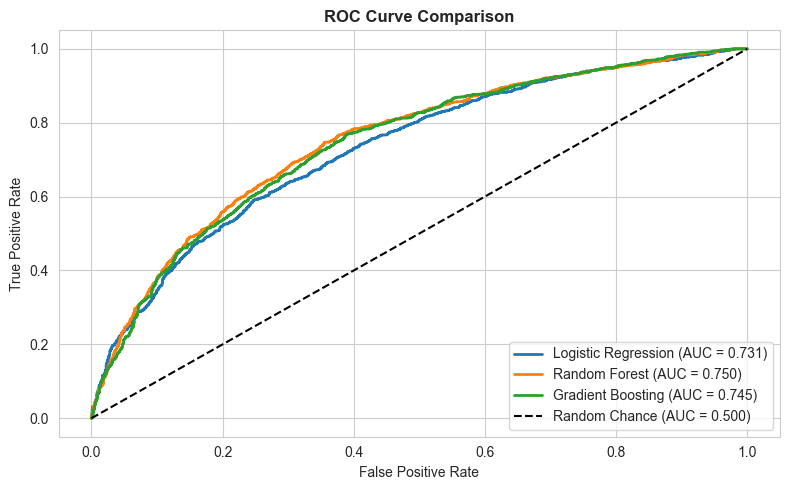

In [12]:
# ROC Curves
plt.figure(figsize=(8, 5))

for name, (model, data_test) in models.items():
    probs = model.predict_proba(data_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, probs)
    auc = roc_auc_score(y_test, probs)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})", linewidth=2)

plt.plot([0, 1], [0, 1], 'k--', label='Random Chance (AUC = 0.500)')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison', fontweight='bold')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

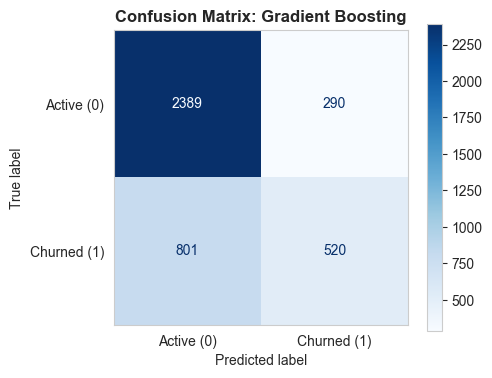

In [13]:
# Confusion Matrix for Gradient Boosting
best_preds = gb_model.predict(X_test)
cm = confusion_matrix(y_test, best_preds)

fig, ax = plt.subplots(figsize=(5, 4))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Active (0)', 'Churned (1)'])
disp.plot(cmap='Blues', ax=ax, values_format='d')
plt.title('Confusion Matrix: Gradient Boosting', fontweight='bold')
plt.grid(False)
plt.tight_layout()
plt.show()

## Step 9: Top 10 Most Important Features

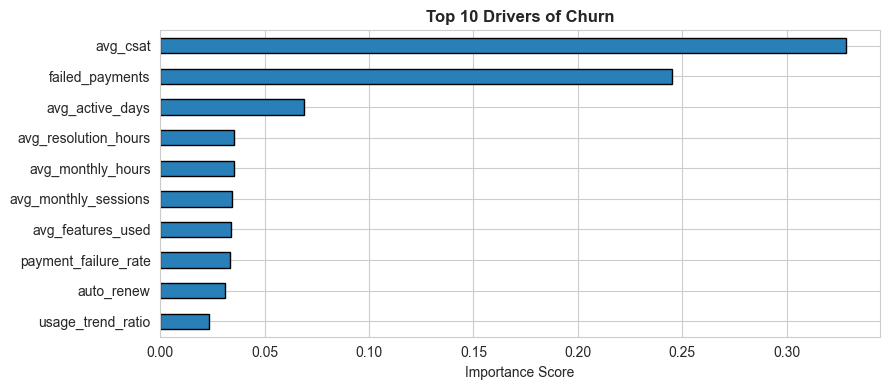

Top 5 Drivers of Churn:
  1. avg_csat                  : 0.3283
  2. failed_payments           : 0.2450
  3. avg_active_days           : 0.0686
  4. avg_resolution_hours      : 0.0353
  5. avg_monthly_hours         : 0.0352


In [14]:
feat_importances = pd.Series(gb_model.feature_importances_, index=X_encoded.columns)
top_features = feat_importances.sort_values(ascending=False).head(10)

plt.figure(figsize=(9, 4))
top_features.plot(kind='barh', color='#2980b9', edgecolor='black')
plt.title('Top 10 Drivers of Churn', fontweight='bold')
plt.xlabel('Importance Score')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

print("Top 5 Drivers of Churn:")
for rank, (feat, score) in enumerate(top_features.head(5).items(), 1):
    print(f"  {rank}. {feat:25s} : {score:.4f}")

## Summary & Next Step

### Key Takeaways:
- **Gradient Boosting** achieved the best overall balance: **0.745 ROC-AUC** and highest Recall / F1-score.
- **Top signals driving churn**: Low CSAT ratings (`avg_csat`), failed billing attempts (`failed_payments`), and low active days (`avg_active_days`).

---

